# <u>Partie 3 : Segmentation des clients</u>

**<u>Objectif</u>**

L'objectif ici est de donner au manager une vision claire des différents types de clients, de ce qu'ils rapportent et coûtent, et des actions adaptées à chacun.

**<u>Démarche</u>**

1. Construire une base avec **une ligne par client** (`user_id`) sur une fenêtre d'observation commune
2. Choisir des variables **de comportement et de valeur** pour former les segments
3. Appliquer un **K-means** sur ces variables standardisées, en choisissant le nombre de segments selon des critères internes et la **stabilité**
4. Décrire chaque segment, y compris avec des variables **non utilisées** pour le former (genre, statut professionnel, région, départ du client) : si elles diffèrent entre segments, la segmentation capte quelque chose de réel
5. Traduire chaque segment en enjeux et en actions

**<u>Pourquoi un clustering plutôt qu'un simple profilage par règles ?</u>**

Un profilage répond à des questions posées à l'avance (« les familles consomment-elles plus ? »). Le clustering fait émerger des **combinaisons** que l'on n'aurait pas forcément cherchées, par exemple des clients récents, sans aucun remboursement et en échec de paiement. 

### Chargement des packages requis 

In [56]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

### Modules du projet

In [57]:
sys.path.insert(0, str(Path.cwd().parent))
from src.config import DATE_EXTRACTION, DOSSIER_PROPRE
from src.style import (ENCRE, PALETTE, appliquer_style, etiqueter_barres, format_milliers, format_pct, nb,
                       rampe_divergente, sauver)

### Réglages d'affichage

In [58]:
appliquer_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

### Chargement des données 

In [59]:
contrats = pd.read_pickle(DOSSIER_PROPRE / "contrats.pkl")
stripe = pd.read_pickle(DOSSIER_PROPRE / "stripe.pkl")
remboursements = pd.read_pickle(DOSSIER_PROPRE / "remboursements.pkl")

## 1. Base clients

**Fenêtre d'observation** : Les remboursements n'existent qu'à partir du 05/06/2025 (partie 2). Pour comparer équitablement la consommation des clients, on va regarder seulement la fenêtre (05/06/2025 au 19/10/2026, environ 16 mois) et on va rapporter les montants au **nombre de mois pendant lesquels le client était couvert** dans la fenêtre.

**Population retenue** : Il s'agit des clients couverts au moins un mois dans la fenêtre, avec une formule de la gamme Vita et un historique de paiement Stripe.

#### Paramètres de la fenêtre d'analyse

In [60]:
DEBUT_FENETRE = remboursements["created_at"].min().normalize()
JOURS_FENETRE = (DATE_EXTRACTION - DEBUT_FENETRE).days
NIVEAUX = {"Vita Découverte": 1, "Vita Bronze": 2, "Vita Silver": 3, "Vita Gold": 4}

#### Contrats valides et durée d'exposition

In [61]:
valides = contrats[~contrats["flag_annule_avant_effet"] & ~contrats["flag_effet_futur"]].copy()
fin = valides["closed_date"].fillna(DATE_EXTRACTION).clip(upper=DATE_EXTRACTION)
valides["fin"] = fin
valides["jours_exposes"] = (fin - valides["start_date"].clip(lower=DEBUT_FENETRE)).dt.days.clip(lower=0)

#### Table clients : profil, contrat et exposition

In [62]:
# Caractéristiques du contrat le plus récent de chaque client

dernier = valides.sort_values("start_date").groupby("user_id").tail(1).set_index("user_id")
par_client = valides.groupby("user_id")
clients = pd.DataFrame({
    "age": dernier["age"],
    "genre": dernier["gender"],
    "statut_pro": dernier["professional_status"],
    "canal": dernier["canal_acquisition"],
    "departement": dernier["departement"],
    "produit": dernier["product_name"],
    "niveau_garantie": dernier["product_name"].map(NIVEAUX),
    "cotisation_mensuelle": dernier["price"],
    "nb_beneficiaires": par_client["nb_beneficiaires"].max(),
    "anciennete_mois": (par_client["fin"].max() - par_client["start_date"].min()).dt.days / 30.44,

    # quelques clients ont deux contrats simultanés : on plafonne l'exposition à la durée de la fenêtre
    
    "exposition_mois": par_client["jours_exposes"].sum().clip(upper=JOURS_FENETRE) / 30.44,
    "actif": par_client["est_ferme"].agg(lambda x: (~x).any()),
})

#### Remboursements et paiements par client

In [63]:
# Remboursements (déjà tous dans la fenêtre)

rb = remboursements.dropna(subset=["user_id"])
agg_r = rb.groupby("user_id").agg(nb_demandes=("claim_id", "size"), nb_approuvees=("is_approved", "sum"),
                                   montant_rembourse=("amount_refund_mutual", lambda x: x[x > 0].sum()))

# Paiements : tentatives sur tout l'historique, cotisations encaissées sur la fenêtre

st = stripe[stripe["status"].isin(["Paid", "Failed"]) & ~stripe["flag_contrat_inconnu"]].merge(
    contrats[["contract_id", "user_id"]], on="contract_id")
agg_s = st.groupby("user_id").agg(nb_tentatives=("status", "size"), nb_echecs=("status", lambda x: (x == "Failed").sum()))
cotis = st[(st["status"] == "Paid") & (st["created_at"] >= DEBUT_FENETRE)].groupby("user_id")["montant_net"].sum()

#### Fusion et indicateurs calculés

In [64]:
clients = clients.join(agg_r).join(agg_s).join(cotis.rename("cotisations_fenetre"))
clients[["nb_demandes", "nb_approuvees", "montant_rembourse", "cotisations_fenetre"]] = \
    clients[["nb_demandes", "nb_approuvees", "montant_rembourse", "cotisations_fenetre"]].fillna(0)
clients["conso_mensuelle"] = clients["montant_rembourse"] / clients["exposition_mois"]
clients["taux_echec_paiement"] = clients["nb_echecs"] / clients["nb_tentatives"]
clients["taux_refus"] = (1 - clients["nb_approuvees"] / clients["nb_demandes"]).where(clients["nb_demandes"] > 0)

#### Base d'analyse et entonnoir de sélection

In [65]:
entonnoir = pd.Series({
    "clients (hors annulations avant effet)": len(clients),
    "couverts au moins 1 mois dans la fenêtre": (clients["exposition_mois"] >= 1).sum(),
    "dont formule Vita": ((clients["exposition_mois"] >= 1) & clients["niveau_garantie"].notna()).sum(),
    "dont avec historique de paiement Stripe": ((clients["exposition_mois"] >= 1) & clients["niveau_garantie"].notna()
                                                & clients["nb_tentatives"].notna()).sum(),
})

base = clients[(clients["exposition_mois"] >= 1) & clients["niveau_garantie"].notna() & clients["nb_tentatives"].notna()].copy()
print(f"Fenêtre : du {DEBUT_FENETRE:%d/%m/%Y} au {DATE_EXTRACTION:%d/%m/%Y}")
entonnoir.to_frame("clients")

Fenêtre : du 05/06/2025 au 19/10/2026


,clients
clients (hors annulations avant effet),11706
couverts au moins 1 mois dans la fenêtre,9110
dont formule Vita,9106
dont avec historique de paiement Stripe,8470


#### Lecture de notre base clients 

In [66]:
base.head()

,age,genre,statut_pro,canal,departement,produit,niveau_garantie,cotisation_mensuelle,nb_beneficiaires,anciennete_mois,exposition_mois,actif,nb_demandes,nb_approuvees,montant_rembourse,nb_tentatives,nb_echecs,cotisations_fenetre,conso_mensuelle,taux_echec_paiement,taux_refus
user_id,,,,,,,,,,,,,,,,,,,,,
000e4827-6e94-4e61-a9f0-072fea37b4cb,27.90,FEMALE,UNKNOWN,Non renseigné,34,Vita Bronze,2.00,55.99,1,21.35,16.46,True,11.00,10.00,276.81,21.00,0.00,860.59,16.82,0.00,0.09
00100a57-8549-4afc-be82-e7d566610b72,37.30,FEMALE,UNKNOWN,Non renseigné,25,Vita Découverte,1.00,85.43,1,23.55,16.46,True,11.00,10.00,265.30,25.00,0.00,841.75,16.12,0.00,0.09
0011b6be-aa37-4469-9c09-face999d0cd7,28.90,FEMALE,UNKNOWN,Non renseigné,31,Vita Découverte,1.00,40.23,1,29.66,12.55,False,9.00,8.00,250.00,34.00,4.00,496.17,19.92,0.12,0.11
0014ce37-e9bb-4ccb-a315-d604e9251f16,36.50,FEMALE,JOB_SEEKER,Non renseigné,16,Vita Découverte,1.00,50.03,1,2.37,2.37,True,0.00,0.00,0.00,4.00,2.00,88.76,0.00,0.50,NaN
00168bb7-e225-476a-b677-bddb84633b34,48.30,MALE,SELF_EMPLOYED,Réseaux sociaux,92,Vita Bronze,2.00,95.26,1,2.23,2.23,False,0.00,0.00,0.00,12.00,10.00,125.99,0.00,0.83,NaN


In [67]:
base.tail()

,age,genre,statut_pro,canal,departement,produit,niveau_garantie,cotisation_mensuelle,nb_beneficiaires,anciennete_mois,exposition_mois,actif,nb_demandes,nb_approuvees,montant_rembourse,nb_tentatives,nb_echecs,cotisations_fenetre,conso_mensuelle,taux_echec_paiement,taux_refus
user_id,,,,,,,,,,,,,,,,,,,,,
ffe8576e-74d0-48da-ae80-2219e4815e0e,25.90,FEMALE,CIVIL_SERVANT,Parrainage,95,Vita Découverte,1.00,41.12,1,12.58,12.58,False,4.00,3.00,55.66,21.00,8.00,525.71,4.42,0.38,0.25
ffee0254-ebdd-407c-97ea-7c37ae300a81,38.20,FEMALE,CIVIL_SERVANT,Réseaux sociaux,38,Vita Bronze,2.00,69.52,1,13.57,13.57,True,11.00,9.00,208.07,16.00,2.00,932.88,15.34,0.12,0.18
fff03af0-ae6d-450c-bb85-4770f72b1933,44.60,FEMALE,PARENT_AT_HOME,"Organique (fiche Google, IA, avis, site)",95,Vita Découverte,1.00,59.42,1,5.62,5.62,True,4.00,3.00,75.00,6.00,0.00,336.52,13.35,0.00,0.25
fffe18cd-41c3-436e-aabb-667ac7a93310,29.50,FEMALE,SELF_EMPLOYED,Publicité moteur de recherche,30,Vita Découverte,1.00,43.70,1,5.22,5.22,True,2.00,2.00,50.00,7.00,1.00,245.29,9.57,0.14,0.00
ffff6d45-e4ef-4eb7-a20f-a4096f91e748,29.20,FEMALE,JOB_SEEKER,Non renseigné,13,Vita Bronze,2.00,59.51,1,8.54,8.54,True,4.00,3.00,61.90,9.00,0.00,535.59,7.25,0.00,0.25


In [68]:
base.shape 

(8470, 21)

In [69]:
base.columns

Index(['age', 'genre', 'statut_pro', 'canal', 'departement', 'produit',
       'niveau_garantie', 'cotisation_mensuelle', 'nb_beneficiaires',
       'anciennete_mois', 'exposition_mois', 'actif', 'nb_demandes',
       'nb_approuvees', 'montant_rembourse', 'nb_tentatives', 'nb_echecs',
       'cotisations_fenetre', 'conso_mensuelle', 'taux_echec_paiement',
       'taux_refus'],
      dtype='str')

In [70]:
base.isna().sum()

age                        0
genre                      0
statut_pro                 0
canal                      0
departement                4
produit                    0
niveau_garantie            0
cotisation_mensuelle       0
nb_beneficiaires           0
anciennete_mois            0
exposition_mois            0
actif                      0
nb_demandes                0
nb_approuvees              0
montant_rembourse          0
nb_tentatives              0
nb_echecs                  0
cotisations_fenetre        0
conso_mensuelle            0
taux_echec_paiement        0
taux_refus              1776
dtype: int64

In [71]:
base.duplicated().sum()

np.int64(0)

In [72]:
base.info()

<class 'pandas.DataFrame'>
Index: 8470 entries, 000e4827-6e94-4e61-a9f0-072fea37b4cb to ffff6d45-e4ef-4eb7-a20f-a4096f91e748
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   8470 non-null   float64
 1   genre                 8470 non-null   str    
 2   statut_pro            8470 non-null   str    
 3   canal                 8470 non-null   str    
 4   departement           8466 non-null   str    
 5   produit               8470 non-null   str    
 6   niveau_garantie       8470 non-null   float64
 7   cotisation_mensuelle  8470 non-null   float64
 8   nb_beneficiaires      8470 non-null   int64  
 9   anciennete_mois       8470 non-null   float64
 10  exposition_mois       8470 non-null   float64
 11  actif                 8470 non-null   bool   
 12  nb_demandes           8470 non-null   float64
 13  nb_approuvees         8470 non-null   float64
 14  montant_rembourse    

Ajout de la variable base **freq_demandes** à la base client

In [73]:
base["freq_demandes"] = base["nb_approuvees"] / base["exposition_mois"]

In [74]:
base.columns

Index(['age', 'genre', 'statut_pro', 'canal', 'departement', 'produit',
       'niveau_garantie', 'cotisation_mensuelle', 'nb_beneficiaires',
       'anciennete_mois', 'exposition_mois', 'actif', 'nb_demandes',
       'nb_approuvees', 'montant_rembourse', 'nb_tentatives', 'nb_echecs',
       'cotisations_fenetre', 'conso_mensuelle', 'taux_echec_paiement',
       'taux_refus', 'freq_demandes'],
      dtype='str')

In [75]:
base.duplicated().sum()

np.int64(0)

In [76]:
base.isna().sum()

age                        0
genre                      0
statut_pro                 0
canal                      0
departement                4
produit                    0
niveau_garantie            0
cotisation_mensuelle       0
nb_beneficiaires           0
anciennete_mois            0
exposition_mois            0
actif                      0
nb_demandes                0
nb_approuvees              0
montant_rembourse          0
nb_tentatives              0
nb_echecs                  0
cotisations_fenetre        0
conso_mensuelle            0
taux_echec_paiement        0
taux_refus              1776
freq_demandes              0
dtype: int64

Il y a 4 valeurs manquantes au niveau de la colonne departement. On va supprimer les lignes concernées.

In [77]:
base = base.dropna(subset=["departement"]).copy()

In [78]:
base.shape

(8466, 22)

Il y a 1776 valeurs manquantes au niveau de la colonne taux_refus. Ces vides ne sont pas des oublis de saisie. Un client sans aucune demande n’a pas de taux de refus. Donc, ces valeurs manquantes ne causent pas de problème dans ce contexte. On les laisse comme ça.

**Signification de chaque variable de la base client**

| Variable | Signification |
|---|---|
| `age` | Âge du client (en années) |
| `genre` | Genre du client |
| `statut_pro` | Situation professionnelle (salarié, indépendant, demandeur d'emploi, etc.) |
| `canal` | Canal par lequel le client a été acquis (pub, parrainage, emailing, etc.) |
| `departement` | Département de résidence |
| `produit` | Formule souscrite (Vita Découverte, Bronze, Silver, Gold) |
| `niveau_garantie` | La formule en chiffre, de 1 (Découverte) à 4 (Gold) |
| `cotisation_mensuelle` | Prix mensuel du contrat, en € |
| `nb_beneficiaires` | Nombre de personnes couvertes par le contrat |
| `anciennete_mois` | Durée écoulée depuis la souscription, en mois |
| `exposition_mois` | Nombre de mois de couverture pendant la période où l'on observe les remboursements |
| `actif` | `True` si le client a encore un contrat en cours |
| `nb_demandes` | Nombre de demandes de remboursement |
| `nb_approuvees` | Nombre de demandes acceptées |
| `montant_rembourse` | Total remboursé au client, en € |
| `nb_tentatives` | Nombre de tentatives de prélèvement |
| `nb_echecs` | Nombre de prélèvements échoués |
| `cotisations_fenetre` | Cotisations réellement encaissées sur la période d'observation, en € |
| `conso_mensuelle` | Remboursement moyen par mois de couverture (`montant_rembourse` ÷ `exposition_mois`) |
| `taux_echec_paiement` | Part des prélèvements échoués (`nb_echecs` ÷ `nb_tentatives`) |
| `taux_refus` | Part des demandes refusées (vide pour les 1 776 clients sans aucune demande, d'où 6 694 valeurs seulement) |
| `freq_demandes` | Nombre moyen de demandes approuvées par mois de couverture (`nb_approuvees` ÷ `exposition_mois`). Variable créée plus tard, dans l'étape de corrélation |

## 2. Choix des variables

Le Kmeans est appliqué aux variables continues. D'où le choix des variables candidates ci-dessous.

In [79]:
candidates = {
    "age": "âge",
    "niveau_garantie": "niveau de garantie",
    "cotisation_mensuelle": "cotisation",
    "nb_beneficiaires": "nb bénéficiaires",
    "anciennete_mois": "ancienneté",
    "exposition_mois": "exposition",
    "nb_demandes": "nb demandes",
    "nb_approuvees": "nb approuvées",
    "montant_rembourse": "montant remboursé",
    "nb_tentatives": "nb tentatives",
    "nb_echecs": "nb échecs",
    "cotisations_fenetre": "cotisations encaissées",
    "conso_mensuelle": "consommation",
    "taux_echec_paiement": "échec paiement",
    "taux_refus": "taux de refus",
    "freq_demandes": "fréquence demandes",
}

### Calcul de la corrélation de spearman entre ces variables 

Ici, j'ai fait le choix de corrélation de rang de spearman et non corrélation linéaire de pearson à cause de l'asymétrie des distributions des variables candidates. 

In [80]:
corr = base[list(candidates)].corr(method="spearman").rename(index=candidates, columns=candidates)

### Matrice de corrélation entre les variables candidates

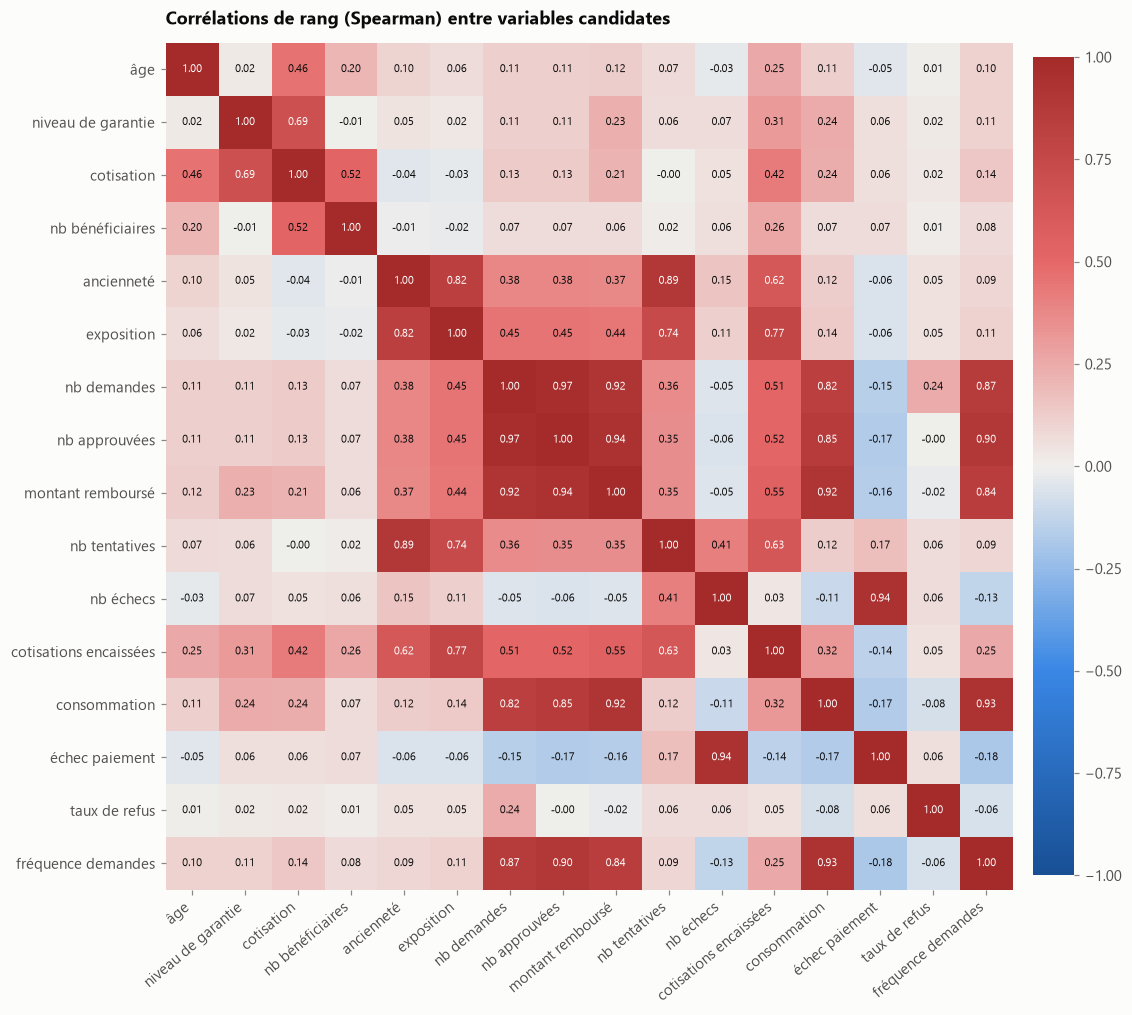

In [81]:
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr.to_numpy(), cmap=rampe_divergente(), vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else ENCRE["principale"])
ax.grid(False)
ax.spines[:].set_visible(False)
barre = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
barre.outline.set_visible(False)
ax.set_title("Corrélations de rang (Spearman) entre variables candidates")
sauver(fig, "p3_correlations")
plt.show()

### Choix des variables

**Règle de sélection** : lorsque deux variables ont une corrélation de Spearman supérieure ou égale à 0,80, on n'en conserve qu'une. La matrice fait apparaître trois groupes redondants :

- **durée de présence** (ancienneté, exposition, nombre de tentatives de prélèvement) : on garde l'**ancienneté**, plus lisible ;
- **remboursements** (nombre de demandes, demandes approuvées, montant remboursé, fréquence des demandes, consommation) : on garde la **consommation mensuelle**, comparable d'un client à l'autre ;
- **échecs de paiement** (nombre d'échecs, taux d'échec) : on garde le **taux d'échec**, indépendant du nombre de tentatives.

**Six variables actives** forment les segments :

- **âge** : principal déterminant du besoin de soins et du tarif ;
- **niveau de garantie** (1 = Vita Découverte à 4 = Vita Gold) : le niveau de protection choisi par le client ;
- **nombre de bénéficiaires** : la structure du foyer couvert ;
- **ancienneté** (en mois) : la fidélité ;
- **consommation mensuelle** (€ remboursés par mois d'exposition) : ce que le client coûte ;
- **taux d'échec de paiement** : la fiabilité de l'encaissement.

**Variables écartées des variables actives :**

- la **cotisation mensuelle** reste sous le seuil (corrélation maximale de 0,69 avec le niveau de garantie, 0,52 avec le nombre de bénéficiaires, 0,46 avec l'âge). Je l'écarte car, elle découle de ces trois variables, qui compteraient deux fois dans le calcul des distances. Elle sert à décrire les segments. ;
- le **taux de refus** n'est pas défini pour les clients sans demande (21 % de la base) : plutôt que d'inventer une valeur, nous l'utilisons uniquement pour décrire les segments ;
- les **cotisations encaissées** sont un total qui dépend de la durée de présence (corrélées à 0,77 avec l'exposition) : elles ne sont pas comparables d'un client à l'autre ;
- le **statut professionnel**, le **canal**, le **genre**, le **département** et le **produit** sont des variables qualitatives : elles servent à décrire les segments, pas à les former ;
- le fait d'être **parti ou actif** est ce que l'on cherche à comprendre : il sert de **validation externe** (si les segments ont des taux de départ très différents, ils sont utiles).

## 3. Implementation de Kmeans

Ici, l'inertie et la silhouette sont les deux métriques pour évaluer les performances de mon algorithme Kmeans.

#### Constitution des variables à faire passer dans kmeans

In [82]:
ACTIVES = ["age", "niveau_garantie", "nb_beneficiaires", "anciennete_mois", "conso_mensuelle", "taux_echec_paiement"]
X = base[ACTIVES].copy()

In [83]:
X.describe()

,age,niveau_garantie,nb_beneficiaires,anciennete_mois,conso_mensuelle,taux_echec_paiement
count,8 466.00,8 466.00,8 466.00,8 466.00,8 466.00,8 466.00
mean,32.75,1.66,1.21,14.57,17.75,0.17
std,6.85,0.85,0.61,8.86,27.98,0.24
min,18.60,1.00,1.00,0.79,0.00,0.00
25%,28.10,1.00,1.00,7.33,0.00,0.00
50%,31.70,1.00,1.00,13.57,10.95,0.07
75%,35.90,2.00,1.00,20.53,24.20,0.25
max,84.20,4.00,7.00,43.63,1 268.33,1.00


In [84]:
X.shape

(8466, 6)

#### Détection des outliers
Ici, j'applique les règles des quartiles (1,5xIQR)

In [85]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outlier = (X < q1 - 1.5 * iqr) | (X> q3 + 1.5 * iqr)

pd.DataFrame({"nb_outliers": outlier.sum(),
              "part (%)": (outlier.mean() * 100).round(1)})

,nb_outliers,part (%)
age,283,3.30
niveau_garantie,409,4.80
nb_beneficiaires,1116,13.20
anciennete_mois,37,0.40
conso_mensuelle,392,4.60
taux_echec_paiement,570,6.70


#### Voyons la distribution de chacune des variables 

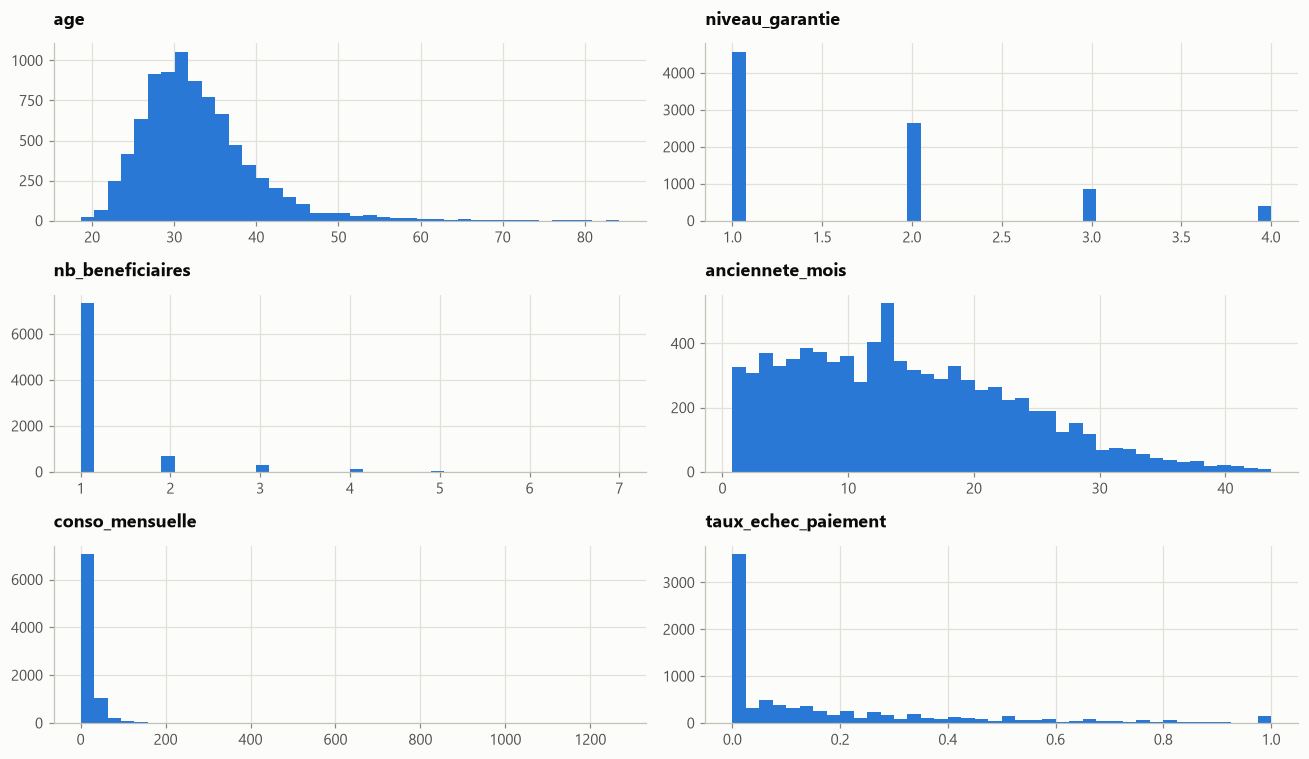

In [86]:
X.hist(bins=40, figsize=(12, 7))
plt.tight_layout()
plt.show()

Coéfficient d'asymétrie de chacune des variables

In [87]:
X.skew().round(2)

age                    1.48
niveau_garantie        1.20
nb_beneficiaires       3.61
anciennete_mois        0.57
conso_mensuelle       13.35
taux_echec_paiement    1.71
dtype: float64

Les variables conso_mensuelle et nb_beneficiaires sont très asymétriques. J'applique donc log(1 + x) à ces deux variables pour traiter ces valeurs extrèmes. (1+x) pour éviter log (0) en prenant log(x)

In [88]:
for col in ["anciennete_mois", "conso_mensuelle"]:
    X[col] = np.log1p(X[col])

#### Standardization des variables 

In [89]:
Z = StandardScaler().set_output(transform="pandas").fit_transform(X)

paramètres du test de stabilité

In [90]:
alea = np.random.RandomState(42)
echantillon = alea.choice(len(Z), min(5000, len(Z)), replace=False)  
Zn = Z.to_numpy()   

calcul des critères pour k = 2 à 9

In [91]:
criteres = []

for k in range(2, 10):

    # Entraînement de K-means

    reference = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=300,
        random_state=0,
        algorithm="elkan"
    ).fit(Zn)

    # Calcul de la silhouette sur l'échantillon

    silhouette = silhouette_score(
        Zn[echantillon],
        reference.labels_[echantillon]
    )

    # Enregistrement des métriques

    criteres.append({
        "k": k,
        "inertie": reference.inertia_,
        "silhouette": silhouette
    })


Création des tableaux et affichage des résultats

In [92]:
criteres = pd.DataFrame(criteres).set_index("k")


criteres.style.format({
    "inertie": "{:,.0f}",
    "silhouette": "{:.3f}"
}, thousands=" ")

,inertie,silhouette
k,,
2,42 432,0.214
3,36 631,0.229
4,31 692,0.197
5,28 482,0.208
6,25 617,0.215
7,23 319,0.207
8,22 032,0.203
9,20 981,0.182


Evolution de l'inertie & Silhouette

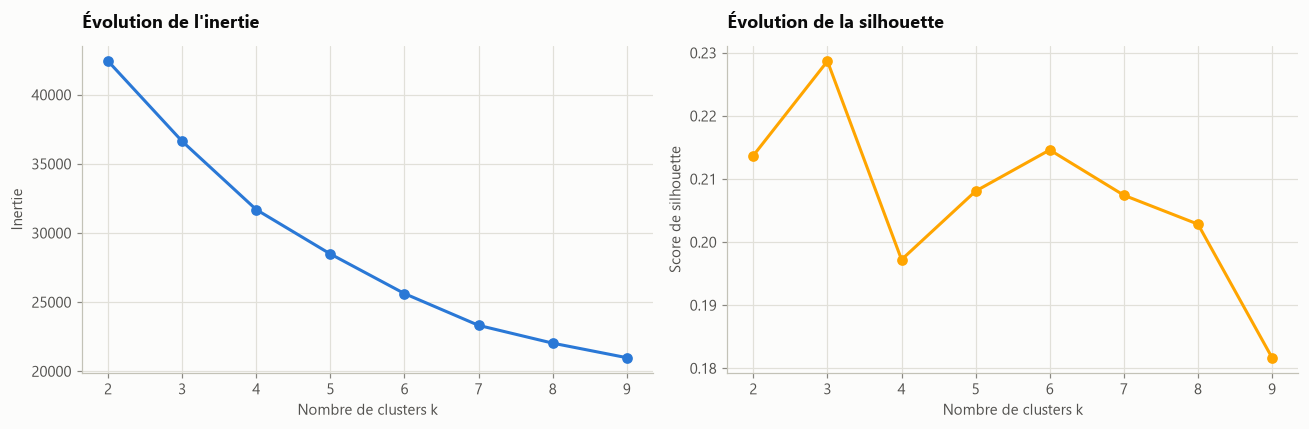

In [93]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Évolution de l'inertie
ax[0].plot(criteres.index, criteres["inertie"], marker="o")
ax[0].set_title("Évolution de l'inertie")
ax[0].set_xlabel("Nombre de clusters k")
ax[0].set_ylabel("Inertie")
ax[0].grid(True)

# Évolution de la silhouette
ax[1].plot(criteres.index, criteres["silhouette"], marker="o", color="orange")
ax[1].set_title("Évolution de la silhouette")
ax[1].set_xlabel("Nombre de clusters k")
ax[1].set_ylabel("Score de silhouette")
ax[1].grid(True)

plt.tight_layout()
plt.show()


En se basant sur l'inertie, le choix optimal du nombre de clusters est 4 alors que 3 est le nombre optimal choisi par la silhouette. Je choisis alors 4 clusters pour une stabilité élevée et un bon compromis entre qualité statistique et interprétabilité métier.

## 4. Résultats

In [94]:
modele = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=300,
    random_state=0,
    algorithm="elkan"
).fit(Zn)

In [95]:
base["segment_id"] = modele.labels_

Examination des centroides 

In [96]:
centres = pd.DataFrame(
    modele.cluster_centers_,
    columns=ACTIVES
)

display(centres.round(2))

,age,niveau_garantie,nb_beneficiaires,anciennete_mois,conso_mensuelle,taux_echec_paiement
0,0.03,0.98,-0.21,0.27,0.64,-0.26
1,0.85,-0.10,3.47,0.07,0.31,0.13
2,-0.05,-0.65,-0.23,0.08,-0.22,-0.36
3,-0.23,0.10,-0.07,-1.00,-0.84,1.97


Nomination des segments 

In [97]:
noms = {
    0: "Clients bien couverts et consommateurs",
    1: "Familles nombreuses",
    2: "Clients à faible consommation",
    3: "Clients à risque de paiement",
}
ORDRE = list(noms.values())
base["segment"] = pd.Categorical(base["segment_id"].map(noms), ORDRE, ordered=True)
COULEUR = dict(zip(ORDRE, PALETTE))
base["segment"].value_counts().reindex(ORDRE)

segment
Clients bien couverts et consommateurs    2708
Familles nombreuses                        460
Clients à faible consommation             4201
Clients à risque de paiement              1097
Name: count, dtype: int64

Fonction de profil d’un groupe de clients

In [98]:
def resume(d):
    return pd.Series({
        "clients": len(d),
        "age_median": d["age"].median(),
        "niveau_moyen": d["niveau_garantie"].mean(),
        "beneficiaires_moyen": d["nb_beneficiaires"].mean(),
        "anciennete_mediane": d["anciennete_mois"].median(),
        "conso_mensuelle_moyenne": d["conso_mensuelle"].mean(),
        "part_sans_remboursement": (d["montant_rembourse"] == 0).mean(),
        "taux_echec_moyen": d["taux_echec_paiement"].mean(),
        "cotisation_mediane": d["cotisation_mensuelle"].median(),
        "taux_refus_moyen": d["taux_refus"].mean(),
        "part_partis": 1 - d["actif"].mean(),
        "S/P apparent": d["montant_rembourse"].sum() / d["cotisations_fenetre"].sum(),
    })

Profil par segment et pour l’ensemble

In [99]:
profil = base.groupby("segment", observed=True).apply(resume, include_groups=False)
profil.insert(1, "part", profil["clients"] / len(base))
profil.loc["Ensemble"] = resume(base).reindex(profil.columns).fillna(1.0)  

Affichage des caractéristiques de chaque segment de client 

In [100]:
profil.style.format({
    "clients": "{:,.0f}", "part": "{:.0%}", "age_median": "{:.0f} ans", "niveau_moyen": "{:.1f}",
    "beneficiaires_moyen": "{:.1f}", "anciennete_mediane": "{:.0f} mois", "conso_mensuelle_moyenne": "{:.1f} €",
    "part_sans_remboursement": "{:.0%}", "taux_echec_moyen": "{:.0%}", "cotisation_mediane": "{:.0f} €",
    "taux_refus_moyen": "{:.0%}", "part_partis": "{:.0%}", "S/P apparent": "{:.0%}"}, thousands=" ")

,clients,part,age_median,niveau_moyen,beneficiaires_moyen,anciennete_mediane,conso_mensuelle_moyenne,part_sans_remboursement,taux_echec_moyen,cotisation_mediane,taux_refus_moyen,part_partis,S/P apparent
segment,,,,,,,,,,,,,
Clients bien couverts et consommateurs,2 708,32%,32 ans,2.5,1.1,16 mois,30.1 €,6%,11%,69 €,17%,36%,38%
Familles nombreuses,460,5%,38 ans,1.6,3.3,14 mois,29.8 €,19%,20%,152 €,21%,45%,22%
Clients à faible consommation,4 201,50%,31 ans,1.1,1.1,14 mois,11.1 €,28%,8%,44 €,20%,37%,24%
Clients à risque de paiement,1 097,13%,30 ans,1.7,1.2,6 mois,7.7 €,64%,63%,58 €,32%,72%,15%
Ensemble,8 466,100%,32 ans,1.7,1.2,14 mois,17.8 €,25%,17%,56 €,20%,41%,29%


ACP en 2 dimensions

In [101]:
acp = PCA(2, random_state=0).fit(Z)
coord = acp.transform(Z)
print(f"Variance expliquée par les 2 premiers axes : {acp.explained_variance_ratio_.sum():.0%}")
pd.DataFrame(acp.components_.T, index=ACTIVES, columns=["axe 1", "axe 2"]).round(2)

Variance expliquée par les 2 premiers axes : 45%


,axe 1,axe 2
age,0.23,0.56
niveau_garantie,0.15,0.27
nb_beneficiaires,0.03,0.68
anciennete_mois,0.54,-0.13
conso_mensuelle,0.57,0.13
taux_echec_paiement,-0.56,0.34


Représentation graphique de chaque segment en dimension d'ACP (les autres clients en gris)

In [102]:
alea = np.random.RandomState(42)
pts = alea.choice(len(coord), min(4000, len(coord)), replace=False)
xy = coord[pts]
seg_pts = base["segment"].to_numpy()[pts]

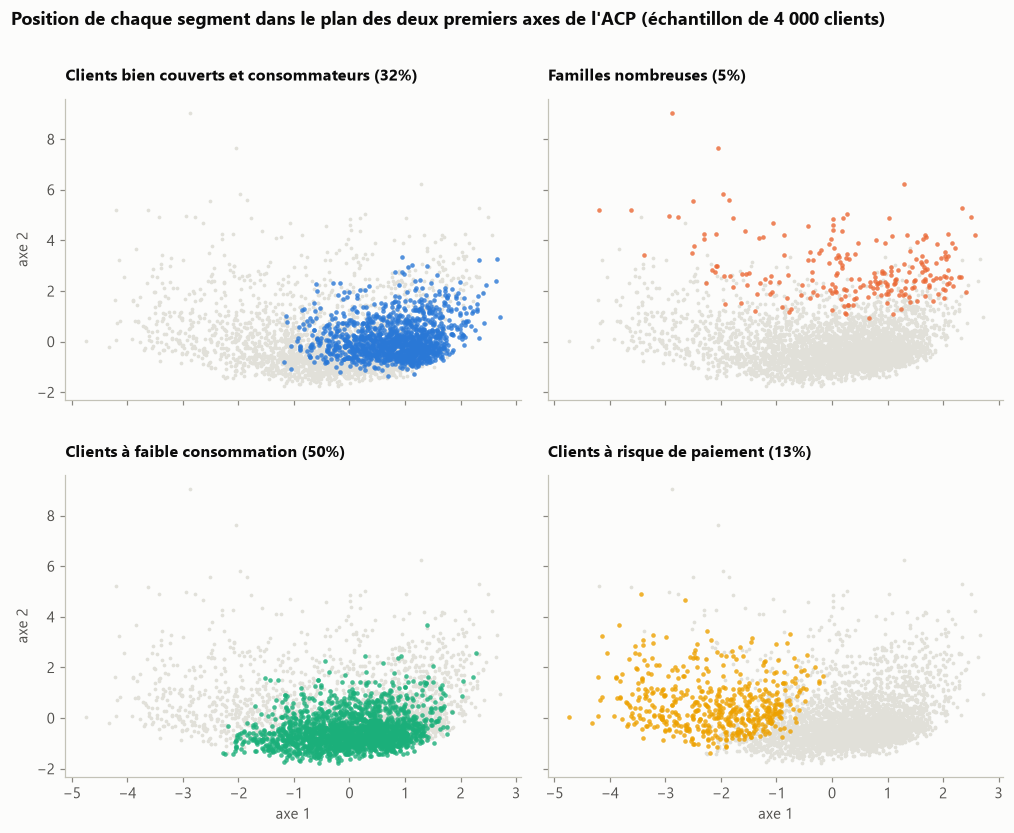

In [103]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.25, "wspace": 0.06})
for ax, seg in zip(axes.flat, ORDRE):
    est_seg = seg_pts == seg
    ax.scatter(xy[~est_seg, 0], xy[~est_seg, 1], s=6, color=ENCRE["grille"], linewidth=0)
    ax.scatter(xy[est_seg, 0], xy[est_seg, 1], s=9, color=COULEUR[seg], linewidth=0, alpha=0.8)
    ax.set_title(f"{seg} ({(base['segment'] == seg).mean():.0%})", fontsize=10.5, loc="left")
    ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel("axe 1")
for ax in axes[:, 0]:
    ax.set_ylabel("axe 2")
fig.suptitle("Position de chaque segment dans le plan des deux premiers axes de l'ACP "
             "(échantillon de 4 000 clients)", x=0.08, ha="left", fontsize=12, fontweight="bold", y=0.98)
sauver(fig, "p3_acp_segments")
plt.show()

Représentation de tous les segments dans un seul graphique

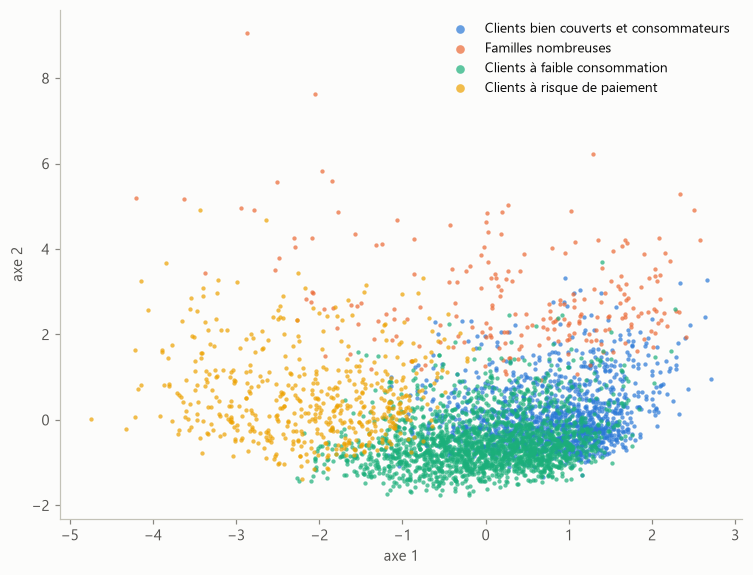

In [104]:
fig, ax = plt.subplots(figsize=(8, 6))
for seg in ORDRE:
    m = seg_pts == seg
    ax.scatter(xy[m, 0], xy[m, 1], s=8, color=COULEUR[seg], linewidth=0, alpha=0.7, label=seg)
ax.legend(markerscale=2, fontsize=9)
ax.set_xlabel("axe 1"); ax.set_ylabel("axe 2"); ax.grid(False)
plt.show()

Poids économique des segments 

In [105]:
sommes = base.groupby("segment", observed=True)[["montant_rembourse", "cotisations_fenetre"]].sum()
poids = pd.DataFrame({
    "part des clients": profil["part"],
    "part des cotisations encaissées": sommes["cotisations_fenetre"] / sommes["cotisations_fenetre"].sum(),
    "part des remboursements": sommes["montant_rembourse"] / sommes["montant_rembourse"].sum(),
}).reindex(ORDRE)

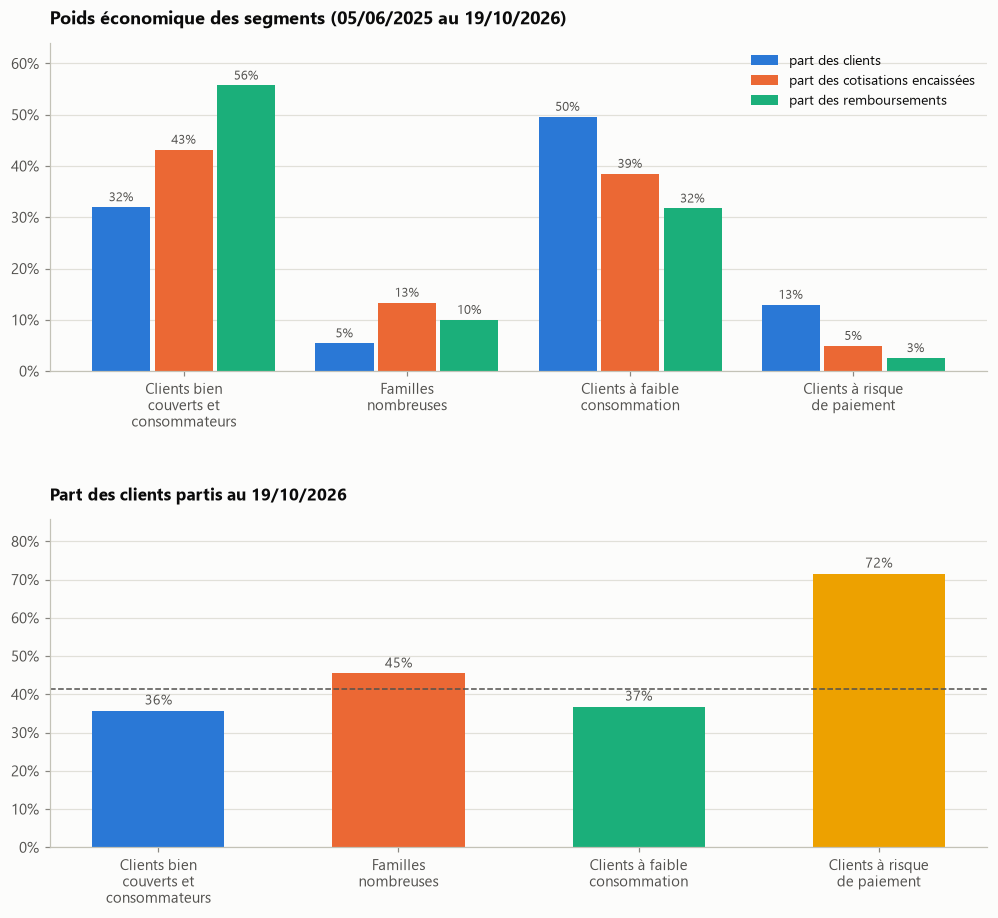

In [106]:
import textwrap
etiquettes = [textwrap.fill(s, 18) for s in ORDRE]
x = np.arange(len(ORDRE))

fig, axes = plt.subplots(2, 1, figsize=(11, 9.5), gridspec_kw={"hspace": 0.45})

#  Poids économique
ax = axes[0]
largeur = 0.26
for i, (col, couleur) in enumerate(zip(poids.columns, PALETTE[:3])):
    barres = ax.bar(x + (i - 1) * (largeur + 0.02), poids[col], largeur, color=couleur, label=col)
    ax.bar_label(barres, labels=[f"{v:.0%}" for v in poids[col]], padding=2, fontsize=8.5, color=ENCRE["secondaire"])
ax.set_xticks(x, etiquettes)
format_pct(ax, "y")
ax.set_ylim(0, poids.to_numpy().max() * 1.15)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Poids économique des segments (05/06/2025 au 19/10/2026)", loc="left")

#  Clients partis

ax = axes[1]
partis = profil["part_partis"].reindex(ORDRE)
barres = ax.bar(x, partis.values, width=0.55, color=[COULEUR[s] for s in ORDRE])
ax.bar_label(barres, labels=[f"{v:.0%}" for v in partis], padding=2, fontsize=9, color=ENCRE["secondaire"])
moyenne_partis = 1 - base["actif"].mean()
ax.axhline(moyenne_partis, color=ENCRE["secondaire"], linewidth=1, linestyle="--")
ax.annotate(f"ensemble : {moyenne_partis:.0%}", (len(ORDRE) - 0.5, moyenne_partis), xytext=(0, 4),
            textcoords="offset points", ha="right", fontsize=9, color=ENCRE["secondaire"])
ax.set_xticks(x, etiquettes)
format_pct(ax, "y")
ax.set_ylim(0, partis.max() * 1.2)
ax.grid(axis="x", visible=False)
ax.set_title("Part des clients partis au 19/10/2026",
             loc="left", fontsize=11)
sauver(fig, "p3_poids_segments")
plt.show()

Caractérisation des segments : genre, région, statut professionnel et formule

In [107]:
IDF = ["75", "77", "78", "91", "92", "93", "94", "95"]
connu = base["statut_pro"] != "UNKNOWN"
par_segment = base.groupby("segment", observed=True)
par_segment_connu = base[connu].groupby("segment", observed=True)

description = pd.DataFrame({
    "part de femmes": par_segment["genre"].agg(lambda x: (x == "FEMALE").mean()),
    "part en Île-de-France": par_segment["departement"].agg(lambda x: x.isin(IDF).mean()),
    "part dans les Bouches-du-Rhône": par_segment["departement"].agg(lambda x: (x == "13").mean()),
    "statut pro renseigné": par_segment["statut_pro"].agg(lambda x: (x != "UNKNOWN").mean()),
    "statut pro le plus fréquent (si renseigné)": par_segment_connu["statut_pro"].agg(lambda x: x.value_counts().index[0]),
    "part de demandeurs d'emploi (si renseigné)": par_segment_connu["statut_pro"].agg(lambda x: (x == "JOB_SEEKER").mean()),
    "formule la plus fréquente": par_segment["produit"].agg(lambda x: x.value_counts().index[0]),
}).reindex(ORDRE)
description.index.name = "segment"

description.style.format({c: "{:.0%}" for c in description.columns
                          if c.startswith("part") or c.startswith("statut pro renseigné")})

,part de femmes,part en Île-de-France,part dans les Bouches-du-Rhône,statut pro renseigné,statut pro le plus fréquent (si renseigné),part de demandeurs d'emploi (si renseigné),formule la plus fréquente
segment,,,,,,,
Clients bien couverts et consommateurs,86%,31%,5%,37%,JOB_SEEKER,26%,Vita Bronze
Familles nombreuses,80%,15%,5%,40%,EMPLOYEE,19%,Vita Découverte
Clients à faible consommation,82%,23%,5%,46%,JOB_SEEKER,29%,Vita Découverte
Clients à risque de paiement,76%,27%,5%,82%,JOB_SEEKER,28%,Vita Découverte


#### Enregistrement de la base segments_clients.

In [108]:
(base[["segment"]].reset_index()
     .rename(columns={"index": "user_id"})
     .to_csv(DOSSIER_PROPRE / "segments_clients.csv", index=False))

pd.read_csv(DOSSIER_PROPRE / "segments_clients.csv")["segment"].value_counts()

segment
Clients à faible consommation             4201
Clients bien couverts et consommateurs    2708
Clients à risque de paiement              1097
Familles nombreuses                        460
Name: count, dtype: int64

## <u>Interprétation business des segments</u>


| Segment | Clients | Cotisations | Remboursements | S/P apparent | Partis |
|---|---|---|---|---|---|
| Bien couverts et consommateurs | 32 % | 43 % | 56 % | 38 % | 36 % |
| Familles nombreuses | 5 % | 13 % | 10 % | 22 % | 45 % |
| Faible consommation | 50 % | 39 % | 32 % | 24 % | 37 % |
| Risque de paiement | 13 % | 5 % | 3 % | 15 % | 72 % |
| **Ensemble** | 100 % | 100 % | 100 % | 29 % | 41 % |

**1. Bien couverts et consommateurs** : C'est le cœur de la valeur. Ce segment regroupe des Clients de 32 ans en Vita Bronze, surreprésentés en Île-de-France (31 %), qui consomment 30 € par mois. Ils apportent 43 % des cotisations mais 56 % des remboursements : c'est le segment le plus sensible à la sinistralité. Il faut donc les fidéliser et éviter les hausses tarifaires brutales.

**2. Familles nombreuses** : petit segment, forte valeur. Il s'agit des foyers de 3,3 bénéficiaires, salariés, en Vita Découverte, peu présents en Île-de-France (15 %). Ils pèsent 13 % des cotisations pour 5 % des clients, mais 45 % sont partis. Il est recommandé d'en faire la priorité de rétention : offre famille, interlocuteur dédié, relance avant résiliation.

**3. Faible consommation**: C'est le volume du portefeuille. La moitié des clients, en Vita Découverte, plus souvent demandeurs d'emploi, qui consomment 11 € par mois. Ils sont rentables mais risquent de résilier faute de percevoir la valeur du contrat. Il est nécessaire alors de rendre cette valeur visible (garanties, remboursements, services) et de proposer une montée en gamme ciblée.

**4. Risque de paiement** : la fuite à l'entrée. Il s'agit des clients récents (6 mois) dont 63 % des prélèvements échouent, et 72 % sont déjà partis. Ils quittent la mutuelle avant d'avoir utilisé leur contrat. Il faut donc sécuriser les premiers mois : prélèvement SEPA, relance avant échéance, nouvelle tentative après les dates de versement des salaires, activation jusqu'au premier remboursement.

**Priorités** : protéger les segments 1 et 2 (37 % des clients, 56 % des cotisations), réduire les départs précoces du segment 4, entretenir la valeur perçue du segment 3.